# Nose occupancy by flip state: does the cue change where mice search?

Each trial has a **flip state**: the target is hidden at the low-y end and the cue is there (flip 0), at the high-y end with the cue there (flip 1), or anywhere in the grid with no cue (flip 2). The cue is an odor in the odor sessions and a stimulus on a monitor in the vision sessions. This notebook draws the aggregate occupancy maps of `occupancy_nose_slides.ipynb` separately for each flip state, to see whether the flip states produce appreciably different maps.

**The catch: a search ends at its target.** In flip 0 the target is always at the low end, so every flip-0 search finishes there, and the map is pulled toward the low end whether or not the mouse uses the cue. Comparing flip 0 with flip 1 or with all of flip 2 mixes that pull with any effect of the cue. So the main comparison here is **matched by target end**: flip 0 against the flip 2 trials whose target was also at the low end, and flip 1 against the flip 2 trials with the target at the high end. The target-end distribution is then the same on both sides (any of the 12 cells of that end), and what differs is the cue.

**What counts.** *Search* is only the time a trial is running, from its first frame (cue on in flip 0/1) until its target is found; the ITI before it is left out, because the next trial's cue is not on yet. *Retrieval* and *consumption* are as in `occupancy_nose.ipynb`, assigned to the trial just found. Trial 0 and unfound trials are left out. Maps are built by `src/occupancy_flip.py` (`python -m src.occupancy_flip`).

**The maps.** Each mouse's map pools all its sessions in an experiment (a session holds only a few minutes of each condition), as relative occupancy (1 = the time a uniform spread would give a bin), smoothed with a Gaussian of `SMOOTH_BINS` bins for display. Mean maps are the mean of the nine mice's maps. Numbers (zone shares, map similarity) use the unsmoothed maps unless stated. Mice are named Mouse 1-9 in order of ID, as in the slides notebook.

The per-session figures and the experience and good-session comparisons of the slides notebook are not repeated here. Figures are saved to `output/slides_flip/`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy import ndimage
from scipy import stats as sps

from src import config as cfg
from src.epochs import EPOCHS
from src.occupancy import X_EDGES, Y_EDGES
from src.occupancy_flip import load_flip_occupancy, TARGET_ENDS     # run `python -m src.occupancy_flip` to rebuild output/occupancy_flip*.npz

EXPERIMENTS = ['odor', 'vision']
EXP_LABEL = {'odor': 'Odor', 'vision': 'Vision'}
EXP_COLOR = {'odor': '#2a78d6', 'vision': '#7a52c7'}
from src.style import INK, MUTED, GRID, PAPER, SLIDE, use_style
PAD = 1.25                                            # scales every gap between panels and every margin around them
use_style(slides=True)
SLIDES_DIR = cfg.OUT_DIR / 'slides_flip'
SLIDES_DIR.mkdir(exist_ok=True)
SMOOTH_BINS = 1                                       # Gaussian sigma, in bins

loaded = [load_flip_occupancy(e) for e in EXPERIMENTS]
ses = pd.concat([l[0] for l in loaded], ignore_index=True)
raw = {epoch: np.concatenate([l[1][epoch] for l in loaded]) for epoch in EPOCHS}     # {epoch: [session, flip, target end, y, x]}, seconds

LOW, MID, HIGH = (TARGET_ENDS.index(z) for z in ('low', 'mid', 'high'))
CONDITIONS = {                                        # name: (flip state, target ends), summed over those ends
    'cue_low':   (0, [LOW]),
    'cue_high':  (1, [HIGH]),
    'none':      (2, [LOW, MID, HIGH]),
    'none_low':  (2, [LOW]),
    'none_high': (2, [HIGH]),
}
LABEL = {'cue_low': 'Cue at low end (flip 0)', 'cue_high': 'Cue at high end (flip 1)', 'none': 'No cue (flip 2)',
         'none_low': 'No cue, target at the low end', 'none_high': 'No cue, target at the high end'}

def seconds(epoch, cond):
    """[session, y, x] seconds of one condition."""
    flip, ends = CONDITIONS[cond]
    return raw[epoch][:, flip, ends].sum(axis=1)

def density(maps):
    """Share of time per bin, scaled so 1 = time spread evenly over the arena."""
    return maps / maps.sum(axis=(-2, -1), keepdims=True) * maps.shape[-2] * maps.shape[-1]

def smooth(m):
    """Gaussian smoothing over the two spatial axes of one map or a stack of them."""
    return ndimage.gaussian_filter(m, (0,) * (m.ndim - 2) + (SMOOTH_BINS, SMOOTH_BINS), mode='nearest')

def mirror(m):
    """The map reflected end for end, so the high-y end is on the left."""
    return m[..., ::-1, :]

MICE = sorted(ses.mouse.unique())
NAME = {m: f'Mouse {k}' for k, m in enumerate(MICE, start=1)}
print('Mouse key:', ', '.join(f'{NAME[m]} = {m}' for m in MICE))

def mouse_maps(epoch, cond, keep=None):
    """{(experiment, mouse): relative-occupancy map}, pooling the mouse's sessions (optionally only those in `keep`)."""
    s = seconds(epoch, cond)
    rows = ses if keep is None else ses[keep]
    return {(e, m): density(s[g.index].sum(axis=0)) for (e, m), g in rows.groupby(['experiment', 'mouse'])}

def mean_map(maps, exp):
    return np.mean([maps[exp, m] for m in MICE], axis=0)

per_session = pd.DataFrame({LABEL[c]: seconds('search', c).sum(axis=(1, 2)) / 60 for c in CONDITIONS}).groupby(ses.experiment).mean()
display(per_session.T.rename_axis('search minutes per session'))

xc, yc = (X_EDGES[:-1] + X_EDGES[1:]) / 2, (Y_EDGES[:-1] + Y_EDGES[1:]) / 2
XX, YY = np.meshgrid(xc, yc)
ports = density(raw['consumption'].sum(axis=(0, 1, 2))) > 10   # the bins the nose is in while the mouse drinks

Mouse key: Mouse 1 = 9000, Mouse 2 = 9002, Mouse 3 = 9003, Mouse 4 = 9004, Mouse 5 = 9005, Mouse 6 = 9006, Mouse 7 = 9007, Mouse 8 = 9008, Mouse 9 = 9009


experiment,odor,vision
search minutes per session,,
Cue at low end (flip 0),8.725176,8.523062
Cue at high end (flip 1),8.872402,9.332027
No cue (flip 2),10.755352,8.897138
"No cue, target at the low end",4.669948,3.812976
"No cue, target at the high end",4.632437,3.929728


In [2]:
RELATIVE = 'Relative occupancy\n(1 = uniform)'
CHANGE = 'Change in\nrelative occupancy'
VMAX = 2.5                                            # smoothed maps peak near 3; values above saturate

def show(ax, m, cmap='magma', vmin=0, vmax=VMAX, title=None, diverging=False):
    """Draw one map with the arena on its side (long axis left to right, low-y end on the left) and its bounds on top."""
    im = ax.imshow(m.T, origin='lower', extent=(0, cfg.FRAME_H, 0, cfg.FRAME_W), cmap=cmap, vmin=vmin, vmax=vmax, interpolation='bilinear')
    line = INK if diverging else 'white'
    # target cells, faint
    for k in range(2, cfg.GRID_ROWS - 1):
        ax.plot([k * cfg.CELL_H] * 2, [cfg.CELL_W, cfg.FRAME_W - cfg.CELL_W], color=line, lw=0.6, alpha=0.3)
    for k in range(2, cfg.GRID_COLS - 1):
        ax.plot([cfg.CELL_H, cfg.FRAME_H - cfg.CELL_H], [k * cfg.CELL_W] * 2, color=line, lw=0.6, alpha=0.3)
    # middle row (the ports' row), dashed
    ax.add_patch(Rectangle((cfg.LOW_MAX_Y, cfg.CELL_W), cfg.HIGH_MIN_Y - cfg.LOW_MAX_Y, cfg.FRAME_W - 2 * cfg.CELL_W,
                           fill=False, edgecolor=line, lw=1.2, ls=(0, (4, 3)), alpha=0.8))
    # edge of the target grid, bold
    ax.add_patch(Rectangle((cfg.CELL_H, cfg.CELL_W), cfg.FRAME_H - 2 * cfg.CELL_H, cfg.FRAME_W - 2 * cfg.CELL_W,
                           fill=False, edgecolor=line, lw=2))
    # camera frame
    ax.add_patch(Rectangle((0, 0), cfg.FRAME_H, cfg.FRAME_W, fill=False, edgecolor=MUTED, lw=1.5, clip_on=False))
    ax.set(xticks=[], yticks=[], xlim=(0, cfg.FRAME_H), ylim=(0, cfg.FRAME_W))
    for side in ax.spines.values():
        side.set_visible(False)
    if title is not None:
        ax.set_title(title)
    return im

ASPECT = cfg.FRAME_W / cfg.FRAME_H                    # height / width of a map drawn on its side

def padded(top, bottom, left, right):
    """Figure-fraction margins, each widened by PAD."""
    return dict(top=1 - (1 - top) * PAD, bottom=bottom * PAD, left=left * PAD, right=1 - (1 - right) * PAD)

def arena_axes(fig, nrows, ncols, top=0.85, bottom=0.09, left=0.03, right=0.97, wgap=0.25, hgap=0.6, cbar=1.4):
    """A centred nrows x ncols block of map panels, as large as fits; gaps and colorbar room in inches, margins in
    figure fractions, all before PAD is applied. Returns the axes and cax(first_row, last_row), which adds a colorbar
    axis beside those rows."""
    W, H = fig.get_size_inches()
    top, bottom, left, right = padded(top, bottom, left, right).values()
    wgap, hgap = wgap * PAD, hgap * PAD
    box_w, box_h = (right - left) * W - cbar, (top - bottom) * H
    w = min((box_w - (ncols - 1) * wgap) / ncols, (box_h - (nrows - 1) * hgap) / nrows / ASPECT)
    h = w * ASPECT
    block_w, block_h = ncols * w + (ncols - 1) * wgap, nrows * h + (nrows - 1) * hgap
    x0 = left * W + ((right - left) * W - block_w - cbar) / 2
    y1 = top * H - (box_h - block_h) / 2
    row_top = lambda r: y1 - r * (h + hgap)
    axes = np.array([[fig.add_axes([(x0 + c * (w + wgap)) / W, (row_top(r) - h) / H, w / W, h / H]) for c in range(ncols)]
                     for r in range(nrows)])

    def cax(first=0, last=nrows - 1, frac=0.9):
        y_hi, y_lo = row_top(first), row_top(last) - h
        pad = (y_hi - y_lo) * (1 - frac) / 2
        return fig.add_axes([(x0 + block_w + 0.25) / W, (y_lo + pad) / H, 0.2 / W, (y_hi - y_lo - 2 * pad) / H])
    return axes, cax

def colorbar(fig, im, cax, label, clipped='max'):
    """A plain colorbar. Values beyond the scale are drawn in the end color, so the end ticks at a `clipped` end
    ('max', 'both' or None) read '≥ vmax' / '≤ vmin'."""
    cb = fig.colorbar(im, cax=cax)
    vmin, vmax = im.get_clim()
    span = vmax - vmin
    ticks = [t for t in cb.get_ticks() if vmin + 0.1 * span <= t <= vmax - 0.1 * span]
    ticks = [vmin] + ticks + [vmax]
    labels = [f'{t:g}'.replace('-', '−') for t in ticks]
    if clipped in ('max', 'both'):
        labels[-1] = f'≥ {labels[-1]}'
    if clipped == 'both':
        labels[0] = f'≤ {labels[0]}'
    cb.set_ticks(ticks, labels=labels)
    cb.set_label(label, fontsize=14); cb.ax.tick_params(labelsize=12); cb.outline.set_visible(False)
    return cb

KEY = 'Low-y end on the left.  Bold line: edge of the target grid.  Dashed: middle row.'

def finish(fig, title, name, key=KEY):
    """Title and footer, both starting at the left edge of the leftmost panel; then save and show."""
    left = min(ax.get_position().x0 for ax in fig.axes)
    fig.suptitle(title, x=left, y=0.98, ha='left', va='top', fontsize=24, fontweight='bold')
    if key:
        fig.text(left, 0.015, key, ha='left', va='bottom', fontsize=13, color=MUTED)
    fig.savefig(SLIDES_DIR / f'{name}.png')
    plt.show()


CUE_KEY = 'Low-y end on the left.  Bold line: edge of the target grid.  Dashed: middle row.'

## 1. The average map in each flip state

Search time while the trial is running, mean of the nine mice. Each flip state's map is scaled to its own time.

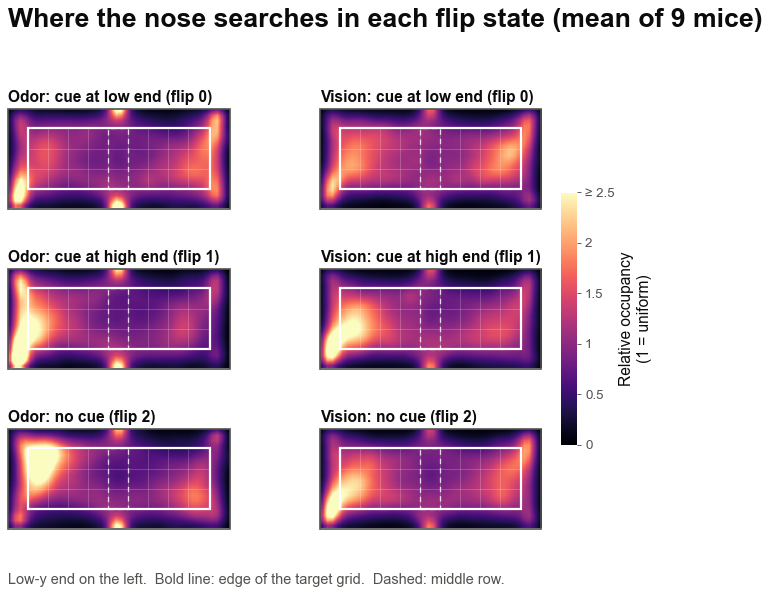

In [3]:
SEARCH = {c: mouse_maps('search', c) for c in CONDITIONS}

fig = plt.figure(figsize=SLIDE)
axes, cax = arena_axes(fig, 3, 2, wgap=0.9)
for row, cond in zip(axes, ['cue_low', 'cue_high', 'none']):
    for ax, exp in zip(row, EXPERIMENTS):
        im = show(ax, smooth(mean_map(SEARCH[cond], exp)))
        ax.set_title(f'{EXP_LABEL[exp]}: {LABEL[cond].lower()}', fontsize=14)
colorbar(fig, im, cax(frac=0.6), RELATIVE)
finish(fig, 'Where the nose searches in each flip state (mean of 9 mice)', '01_search_by_flip')

**Retrieval**, from finding the target to poking a port, by flip state. This is where the target was, so flip 0 and flip 1 differ by design; it is shown as a check that the split is right.

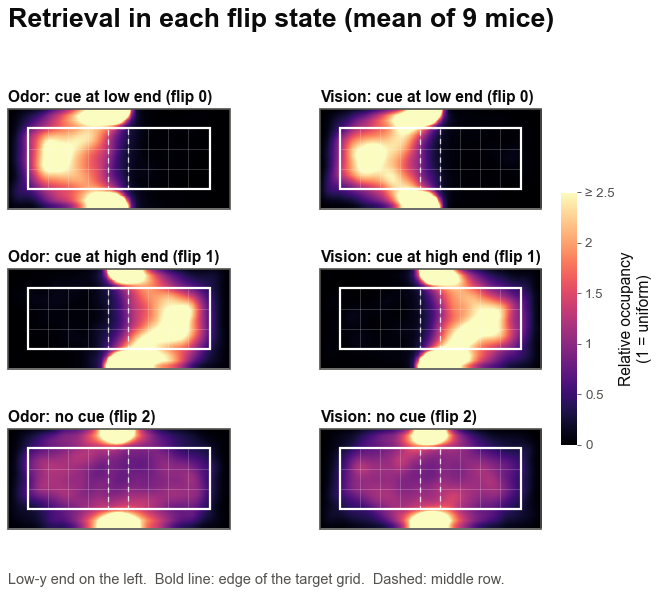

In [4]:
RETRIEVAL = {c: mouse_maps('retrieval', c) for c in ['cue_low', 'cue_high', 'none']}
fig = plt.figure(figsize=SLIDE)
axes, cax = arena_axes(fig, 3, 2, wgap=0.9)
for row, cond in zip(axes, ['cue_low', 'cue_high', 'none']):
    for ax, exp in zip(row, EXPERIMENTS):
        im = show(ax, smooth(mean_map(RETRIEVAL[cond], exp)))
        ax.set_title(f'{EXP_LABEL[exp]}: {LABEL[cond].lower()}', fontsize=14)
colorbar(fig, im, cax(frac=0.6), RELATIVE)
finish(fig, 'Retrieval in each flip state (mean of 9 mice)', '02_retrieval_by_flip')

## 2. Cue trials minus no-cue trials

**Unmatched**: each cue condition minus all no-cue trials. This mixes the cue with the target pull, since the cue trials' targets are all at one end and the no-cue trials' are spread over the grid.

**Matched by target end**: each cue condition minus the no-cue trials with the target at the same end. What is left is the effect of the cue.

Red: more time there with the cue. Blue: less. The two figures share a color scale.

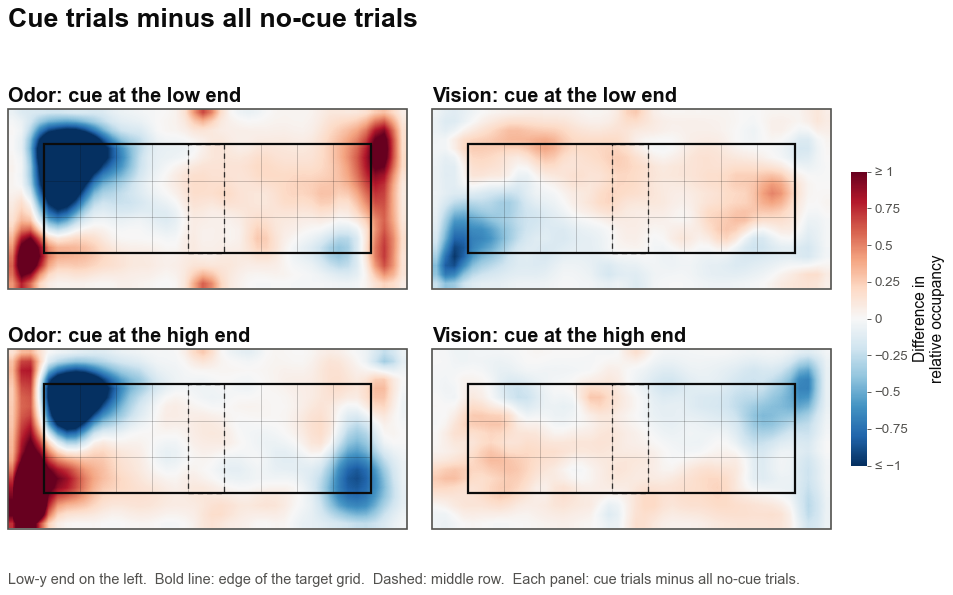

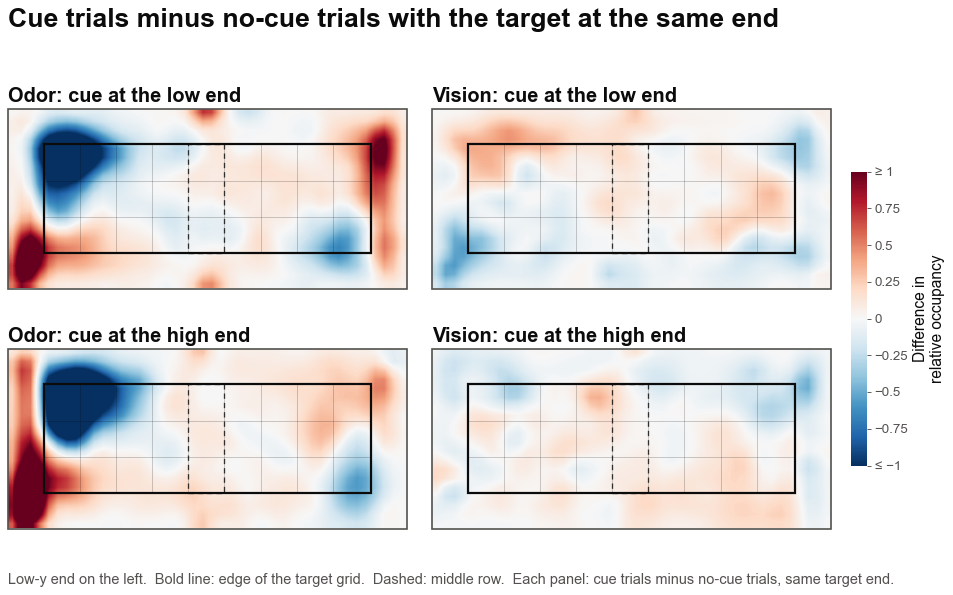

In [5]:
DIFF_VLIM = 1.0
DIFF = {'unmatched': [('cue_low', 'none'), ('cue_high', 'none')], 'matched': [('cue_low', 'none_low'), ('cue_high', 'none_high')]}
TITLE = {'unmatched': 'Cue trials minus all no-cue trials', 'matched': 'Cue trials minus no-cue trials with the target at the same end'}

for k, (kind, pairs) in enumerate(DIFF.items(), start=3):
    fig = plt.figure(figsize=SLIDE)
    axes, cax = arena_axes(fig, 2, 2)
    for row, (a, b) in zip(axes, pairs):
        for ax, exp in zip(row, EXPERIMENTS):
            side = 'cue at the low end' if a == 'cue_low' else 'cue at the high end'
            im = show(ax, smooth(mean_map(SEARCH[a], exp) - mean_map(SEARCH[b], exp)), cmap='RdBu_r', vmin=-DIFF_VLIM, vmax=DIFF_VLIM,
                      diverging=True, title=f'{EXP_LABEL[exp]}: {side}')
    colorbar(fig, im, cax(frac=0.7), 'Difference in\nrelative occupancy', clipped='both')
    finish(fig, TITLE[kind], f'0{k}_difference_{kind}', key=CUE_KEY + ('  Each panel: cue trials minus all no-cue trials.' if kind == 'unmatched'
                                                                         else '  Each panel: cue trials minus no-cue trials, same target end.'))

**Both cue sides together.** The matched difference for the cue at the high end, mirrored end for end and averaged with the one for the cue at the low end, so the **cue end is on the left** in every panel. One map per experiment, then each mouse.

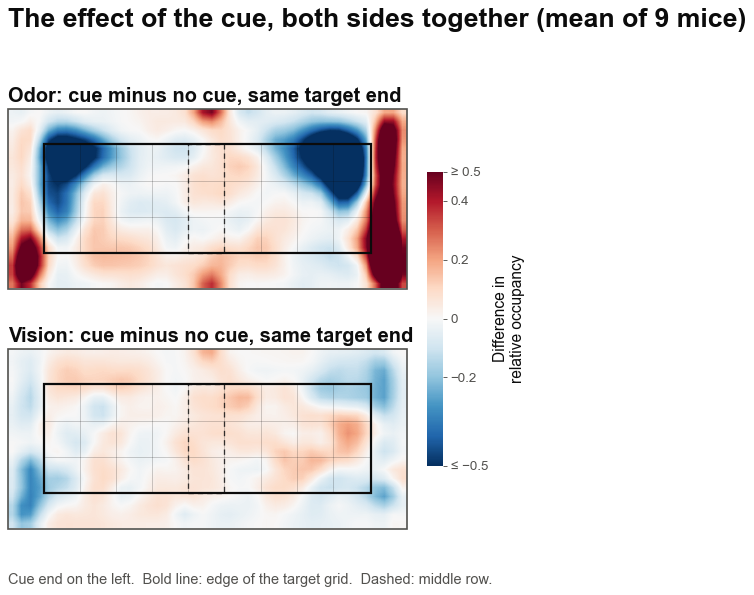

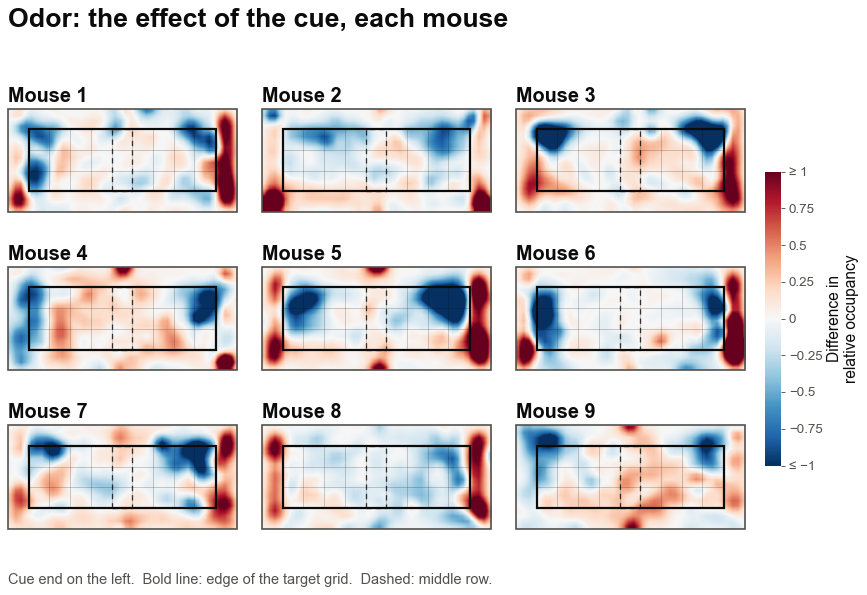

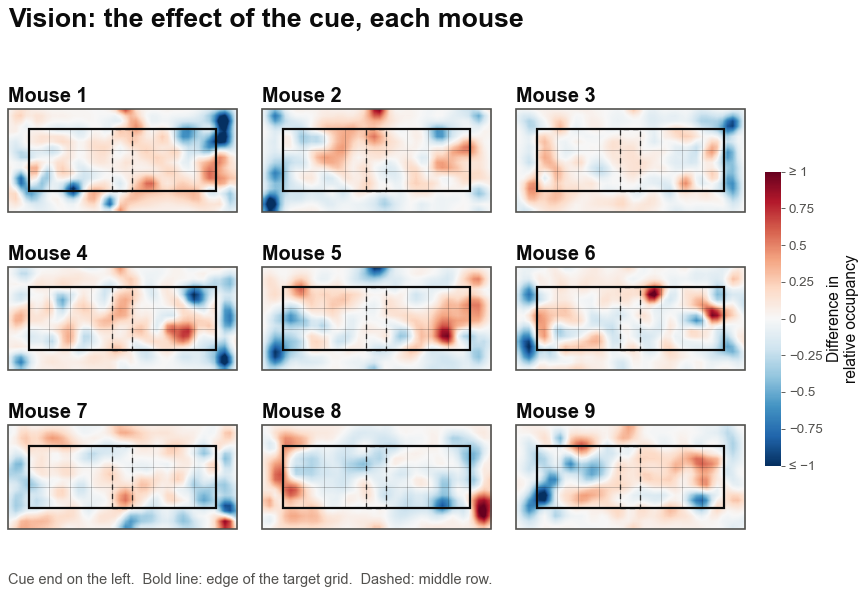

In [6]:
def cue_effect(exp, m):
    """Matched cue-minus-no-cue map for one mouse, the two cue sides averaged with the cue end on the left."""
    low = SEARCH['cue_low'][exp, m] - SEARCH['none_low'][exp, m]
    high = SEARCH['cue_high'][exp, m] - SEARCH['none_high'][exp, m]
    return (low + mirror(high)) / 2

EFFECT = {(e, m): cue_effect(e, m) for e in EXPERIMENTS for m in MICE}
MIRROR_KEY = 'Cue end on the left.  Bold line: edge of the target grid.  Dashed: middle row.'

fig = plt.figure(figsize=SLIDE)
axes, cax = arena_axes(fig, 2, 1)
for ax, exp in zip(axes[:, 0], EXPERIMENTS):
    im = show(ax, smooth(np.mean([EFFECT[exp, m] for m in MICE], axis=0)), cmap='RdBu_r', vmin=-DIFF_VLIM / 2, vmax=DIFF_VLIM / 2,
              diverging=True, title=f'{EXP_LABEL[exp]}: cue minus no cue, same target end')
colorbar(fig, im, cax(frac=0.7), 'Difference in\nrelative occupancy', clipped='both')
finish(fig, 'The effect of the cue, both sides together (mean of 9 mice)', '05_cue_effect_mean', key=MIRROR_KEY)

for exp in EXPERIMENTS:
    fig = plt.figure(figsize=SLIDE)
    axes, cax = arena_axes(fig, 3, 3, hgap=0.55)
    for ax, m in zip(axes.flat, MICE):
        im = show(ax, smooth(EFFECT[exp, m]), cmap='RdBu_r', vmin=-DIFF_VLIM, vmax=DIFF_VLIM, diverging=True, title=NAME[m])
    colorbar(fig, im, cax(frac=0.7), 'Difference in\nrelative occupancy', clipped='both')
    finish(fig, f'{EXP_LABEL[exp]}: the effect of the cue, each mouse', f'06_cue_effect_mice_{exp}', key=MIRROR_KEY)

## 3. Are the maps appreciably different?

**Time at the target's end.** For each mouse, the share of search time with the nose in the end that holds the target (beyond the middle row), on cue trials and on no-cue trials with the target at the same end. The two cue sides are averaged. If the cue drew mice to its end, the cue trials would sit higher.

,cue,no cue,difference,p (paired t),mice higher with cue
share of search time in the target's end,,,,,
Odor,0.384,0.399,-0.015,0.085,2/9
"Odor, low end only",0.446,0.495,-0.049,0.028,2/9
"Odor, high end only",0.321,0.303,+0.018,0.354,5/9
Vision,0.420,0.423,-0.002,0.746,4/9
"Vision, low end only",0.472,0.472,+0.000,0.987,3/9
"Vision, high end only",0.368,0.373,-0.005,0.538,3/9


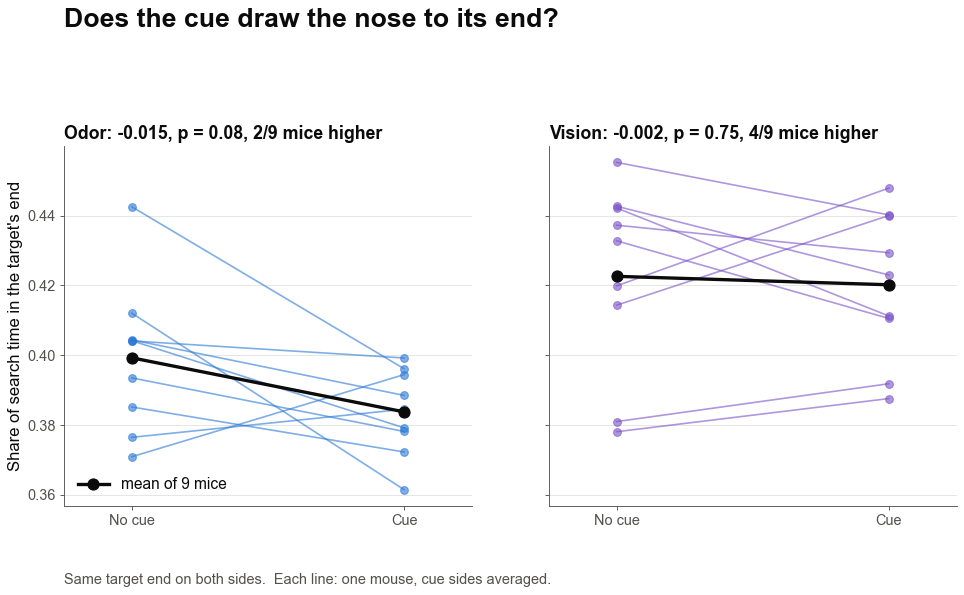

In [7]:
IN_END = {LOW: YY < cfg.LOW_MAX_Y, HIGH: YY >= cfg.HIGH_MIN_Y}

def share_in(maps, mask):
    return {k: v[mask].sum() / v.sum() for k, v in maps.items()}

def end_share(cond):
    end = LOW if cond.endswith('low') else HIGH
    return pd.Series(share_in(SEARCH[cond], IN_END[end]))

target_end = pd.DataFrame({'cue': (end_share('cue_low') + end_share('cue_high')) / 2,
                           'no cue': (end_share('none_low') + end_share('none_high')) / 2})
target_end.index.names = ['experiment', 'mouse']

rows = {}
for exp in EXPERIMENTS:
    t = target_end.loc[exp]
    for side, (a, b) in {'both sides': ('cue', 'no cue')}.items():
        d = t[a] - t[b]
        rows[EXP_LABEL[exp]] = {'cue': t[a].mean(), 'no cue': t[b].mean(), 'difference': d.mean(), 'p (paired t)': sps.ttest_rel(t[a], t[b]).pvalue,
                                'mice higher with cue': f'{int((d > 0).sum())}/{len(d)}'}
    for cond_a, cond_b, name in (('cue_low', 'none_low', 'low end only'), ('cue_high', 'none_high', 'high end only')):
        a, b = end_share(cond_a).loc[exp], end_share(cond_b).loc[exp]
        rows[f'{EXP_LABEL[exp]}, {name}'] = {'cue': a.mean(), 'no cue': b.mean(), 'difference': (a - b).mean(),
                                             'p (paired t)': sps.ttest_rel(a, b).pvalue, 'mice higher with cue': f'{int((a > b).sum())}/{len(a)}'}
end_table = pd.DataFrame(rows).T.rename_axis('share of search time in the target\'s end')
display(end_table.style.format({'cue': '{:.3f}', 'no cue': '{:.3f}', 'difference': '{:+.3f}', 'p (paired t)': '{:.3f}'}))

fig, axes = plt.subplots(1, 2, figsize=SLIDE, sharey=True, gridspec_kw={'wspace': 0.15 * PAD, **padded(top=0.8, bottom=0.12, left=0.1, right=0.97)})
for ax, exp in zip(axes, EXPERIMENTS):
    t = target_end.loc[exp]
    for m, r in t.iterrows():
        ax.plot([0, 1], [r['no cue'], r['cue']], color=EXP_COLOR[exp], lw=1.5, alpha=0.6, marker='o', ms=7)
    ax.plot([0, 1], [t['no cue'].mean(), t['cue'].mean()], color=INK, lw=3, marker='o', ms=10, label='mean of 9 mice')
    res = end_table.loc[EXP_LABEL[exp]]
    ax.set_title(f"{EXP_LABEL[exp]}: {res['difference']:+.3f}, p = {res['p (paired t)']:.2f}, {res['mice higher with cue']} mice higher", fontsize=16)
    ax.set(xticks=[0, 1], xticklabels=['No cue', 'Cue'], xlim=(-0.25, 1.25))
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
axes[0].set_ylabel("Share of search time in the target's end")
axes[0].legend(loc='lower left')
finish(fig, "Does the cue draw the nose to its end?", '07_time_at_target_end',
       key="Same target end on both sides.  Each line: one mouse, cue sides averaged.")

**Where the time goes instead.** The share of search time in each part of the arena, cue trials against no-cue trials with the target at the same end. The high-end condition is mirrored first, so "cue end" is the end with the cue (and the target) in both. Zones: the ring beyond each end row (the grid's outer ring at that end, where no target can be), the end half of the grid itself, the middle row, and the ring along the side walls. Unsmoothed maps; paired t across mice.

In [8]:
in_x = (XX > cfg.CELL_W) & (XX < cfg.FRAME_W - cfg.CELL_W)
ZONES = {'beyond the cue end': YY < cfg.CELL_H,
         'grid, cue end': in_x & (YY >= cfg.CELL_H) & (YY < cfg.LOW_MAX_Y),
         'middle row': (YY >= cfg.LOW_MAX_Y) & (YY < cfg.HIGH_MIN_Y),
         'grid, far end': in_x & (YY >= cfg.HIGH_MIN_Y) & (YY < cfg.FRAME_H - cfg.CELL_H),
         'beyond the far end': YY >= cfg.FRAME_H - cfg.CELL_H,
         'along the side walls': ~in_x & (YY >= cfg.CELL_H) & (YY < cfg.FRAME_H - cfg.CELL_H) & ~((YY >= cfg.LOW_MAX_Y) & (YY < cfg.HIGH_MIN_Y))}

def zone_shares(low, high, exp):
    """Per mouse, share of time in each zone with the cue/target end on the left: low as it is, high mirrored, averaged."""
    return pd.DataFrame({m: {z: (SEARCH[low][exp, m][mask].sum() / SEARCH[low][exp, m].sum() +
                                 mirror(SEARCH[high][exp, m])[mask].sum() / SEARCH[high][exp, m].sum()) / 2
                             for z, mask in ZONES.items()} for m in MICE}).T

rows = {}
for exp in EXPERIMENTS:
    cue, none = zone_shares('cue_low', 'cue_high', exp), zone_shares('none_low', 'none_high', exp)
    for z in ZONES:
        d = cue[z] - none[z]
        rows[(EXP_LABEL[exp], z)] = {'cue': cue[z].mean(), 'no cue': none[z].mean(), 'difference': d.mean(),
                                     'p (paired t)': sps.ttest_rel(cue[z], none[z]).pvalue, 'mice higher with cue': f'{int((d > 0).sum())}/{len(d)}'}
zone_table = pd.DataFrame(rows).T
zone_table.index.names = ['experiment', 'share of search time']
zone_table.style.format({'cue': '{:.3f}', 'no cue': '{:.3f}', 'difference': '{:+.3f}', 'p (paired t)': '{:.4f}'})

**How similar are the maps, against how similar they could be?** Two maps of the same condition still differ by chance, because each holds a finite amount of search. To set the bar, each mouse's sessions are split into odd and even sessions, and the maps compared within a condition (odd against even) and between conditions (odd of one against even of the other). The **disattenuated correlation** is the between-condition correlation divided by the geometric mean of the two within-condition correlations: **1 means the two conditions differ no more than two halves of the same condition do**; lower means a real difference.

Three comparisons, each per mouse:
- **cue against no cue, same target end** (the two cue sides averaged): the effect of the cue.
- **no cue, target at the low end against target at the high end**: the effect of where the target is, with no cue anywhere. This is the size of a difference the method can detect.
- **cue at the low end against cue at the high end**: the two together, which is what an unmatched flip 0 / flip 1 comparison sees.

Smoothed maps (`SMOOTH_BINS`) are used here, so that single-bin noise does not dominate.

cue vs no cue against target low vs high (paired t across mice): {'Odor': 'p = 0.0025', 'Vision': 'p = 0.3661'}


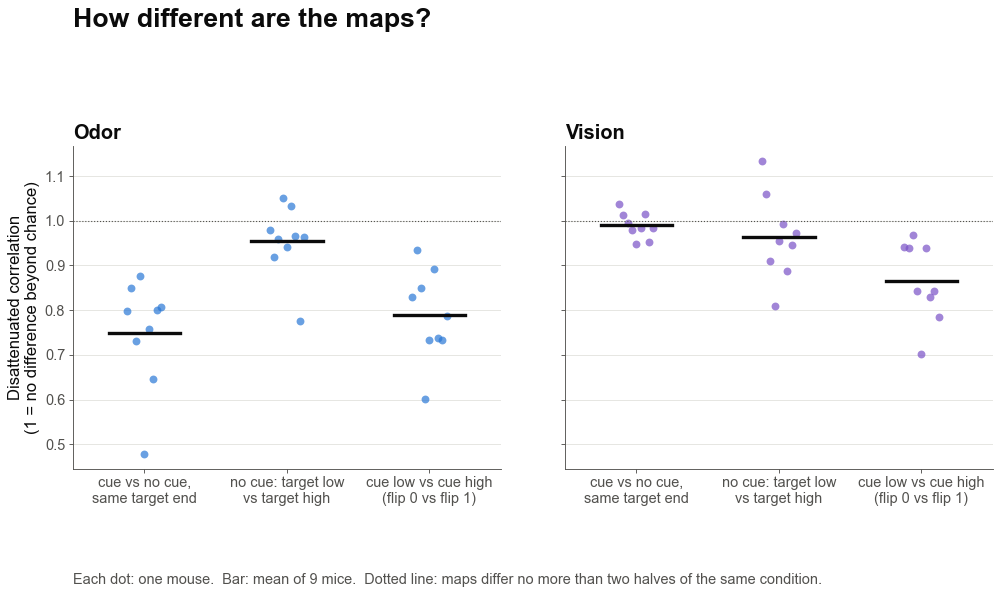

In [9]:
odd = ses.session_num % 2 == 1
HALVES = {c: (mouse_maps('search', c, odd), mouse_maps('search', c, ~odd)) for c in CONDITIONS}

def r(a, b):
    return np.corrcoef(smooth(a).ravel(), smooth(b).ravel())[0, 1]

def disattenuated(a, b, key):
    (a1, a2), (b1, b2) = HALVES[a], HALVES[b]
    within_a, within_b = r(a1[key], a2[key]), r(b1[key], b2[key])
    between = (r(a1[key], b2[key]) + r(a2[key], b1[key])) / 2
    return between / np.sqrt(within_a * within_b)

COMPARE = {'cue vs no cue,\nsame target end': lambda k: (disattenuated('cue_low', 'none_low', k) + disattenuated('cue_high', 'none_high', k)) / 2,
           'no cue: target low\nvs target high': lambda k: disattenuated('none_low', 'none_high', k),
           'cue low vs cue high\n(flip 0 vs flip 1)': lambda k: disattenuated('cue_low', 'cue_high', k)}
similar = pd.DataFrame({name: {(e, m): f((e, m)) for e in EXPERIMENTS for m in MICE} for name, f in COMPARE.items()})
similar.index.names = ['experiment', 'mouse']
summary = similar.groupby('experiment').agg(['mean', 'min', 'max']).T.unstack()
display(summary.style.format('{:.2f}'))
cue_vs_target = {e: sps.ttest_rel(similar.loc[e].iloc[:, 0], similar.loc[e].iloc[:, 1]) for e in EXPERIMENTS}
print('cue vs no cue against target low vs high (paired t across mice):',
      {EXP_LABEL[e]: f'p = {t.pvalue:.4f}' for e, t in cue_vs_target.items()})

fig, axes = plt.subplots(1, 2, figsize=SLIDE, sharey=True, gridspec_kw={'wspace': 0.12 * PAD, **padded(top=0.8, bottom=0.17, left=0.09, right=0.98)})
for ax, exp in zip(axes, EXPERIMENTS):
    s = similar.loc[exp]
    for k, col in enumerate(s.columns):
        jitter = np.linspace(-0.12, 0.12, len(s))
        ax.scatter(k + jitter, s[col], s=50, color=EXP_COLOR[exp], alpha=0.7, lw=0)
        ax.plot([k - 0.25, k + 0.25], [s[col].mean()] * 2, color=INK, lw=3)
    ax.axhline(1, color=MUTED, lw=1, ls=':')
    ax.set(xticks=range(len(s.columns)), xlim=(-0.5, len(s.columns) - 0.5))
    ax.set_xticklabels(s.columns, fontsize=13)
    ax.set_title(EXP_LABEL[exp])
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
axes[0].set_ylabel('Disattenuated correlation\n(1 = no difference beyond chance)')
finish(fig, 'How different are the maps?', '08_map_similarity',
       key='Each dot: one mouse.  Bar: mean of 9 mice.  Dotted line: maps differ no more than two halves of the same condition.')

**Occupancy against distance from the walls**, cue trials against no-cue trials (both target ends, matched), as in the slides notebook. Ports left out; unsmoothed maps. Bands: mean ± SEM across mice.

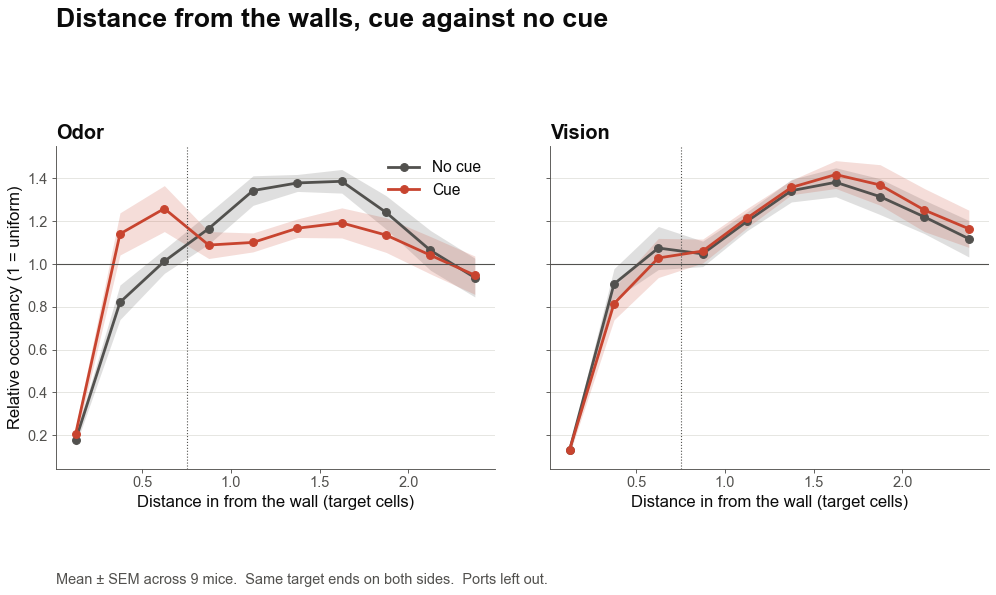

In [10]:
pooled = density(sum(raw[e].sum(axis=(0, 1, 2)) for e in EPOCHS))
reach_x, reach_y = xc[pooled.mean(axis=0) > 0.05], yc[pooled.mean(axis=1) > 0.05]
half_x, half_y = np.diff(X_EDGES)[0] / 2, np.diff(Y_EDGES)[0] / 2
REACH = dict(x0=reach_x.min() - half_x, x1=reach_x.max() + half_x, y0=reach_y.min() - half_y, y1=reach_y.max() + half_y)
wall_dist = np.minimum(np.minimum(XX - REACH['x0'], REACH['x1'] - XX), np.minimum(YY - REACH['y0'], REACH['y1'] - YY))
LANE = 0.75 * cfg.CELL_W
DIST_EDGES = np.arange(0, (REACH['x1'] - REACH['x0']) / 2 + 1, cfg.CELL_W / 4)
band = np.where(ports | (wall_dist <= 0), -1, np.digitize(wall_dist, DIST_EDGES) - 1)
mid_dist = (DIST_EDGES[:-1] + DIST_EDGES[1:]) / 2 / cfg.CELL_W

def matched(a_low, a_high):
    """Per mouse, the two target ends pooled with equal weight."""
    return {k: (SEARCH[a_low][k] + SEARCH[a_high][k]) / 2 for k in SEARCH[a_low]}

def profile(maps, exp):
    return pd.DataFrame({m: [maps[exp, m][band == k].mean() for k in range(len(DIST_EDGES) - 1)] for m in MICE}).T

fig, axes = plt.subplots(1, 2, figsize=SLIDE, sharey=True, gridspec_kw={'wspace': 0.1 * PAD, **padded(top=0.8, bottom=0.17, left=0.08, right=0.98)})
for ax, exp in zip(axes, EXPERIMENTS):
    for maps, color, name in ((matched('none_low', 'none_high'), MUTED, 'No cue'), (matched('cue_low', 'cue_high'), '#c8442f', 'Cue')):
        p = profile(maps, exp)
        ax.fill_between(mid_dist, p.mean() - p.sem(), p.mean() + p.sem(), color=color, alpha=0.18, lw=0)
        ax.plot(mid_dist, p.mean(), color=color, lw=2.5, marker='o', ms=7, label=name)
    ax.axvline(LANE / cfg.CELL_W, color=MUTED, lw=1, ls=':'); ax.axhline(1, color=MUTED, lw=1)
    ax.set_title(EXP_LABEL[exp])
    ax.set_xlabel('Distance in from the wall (target cells)')
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
axes[0].set_ylabel('Relative occupancy (1 = uniform)')
axes[0].legend(loc='upper right')
finish(fig, 'Distance from the walls, cue against no cue', '09_wall_profile', key='Mean ± SEM across 9 mice.  Same target ends on both sides.  Ports left out.')

## Summary

**At a glance the flip states look alike.** Every map has the same overall shape: most time toward the two ends, the brightest spot at the low-y end wall, little in the middle row. The differences are in where along the ends the time goes.

**The visual cue does not change the map.** Matched by target end, cue and no-cue maps differ no more than two halves of the same condition do (disattenuated correlation 0.99, range 0.95-1.04 across mice). No zone's share of search time moves by more than 1.1 percentage points, and the share spent in the target's end is the same with and without the stimulus (42.0% against 42.3%, p = 0.75).

**The odor does change the map, but not by drawing the nose to its end.**
- Matched by target end, odor and no-odor maps are clearly different (disattenuated correlation 0.75, range 0.48-0.88), more different than the maps of no-cue trials with the target at opposite ends (0.95; paired p = 0.003). So where the target is changes the map less than whether the odor is on.
- With the odor on, mice spend **more time beyond the far end row**, the end without the odor and the target: 15.3% of search time against 9.3% (9/9 mice, p = 0.0004). Time beyond the cue's own end row rises a little (8.8% against 7.1%, 7/9 mice, p = 0.11).
- That time comes out of the grid at both ends (cue end 22.3% against 25.4%, far end 27.8% against 31.8%; 8/9 mice lower in each) and a little from the side walls.
- The share of search time in the target's end is, if anything, slightly *lower* with the odor (38.4% against 39.9%, 7/9 mice lower, p = 0.08).
- Most of the difference between the flip-0 and flip-1 maps in the odor sessions (0.79) is this odor effect, not the target's end.

**Reading the results.**
- The odor effect is a shift toward the end walls, mainly the one away from the odor source. The maps cannot say why. Possibilities to check: the airflow (if the odor is carried from the cue end toward an exhaust at the far end, the far wall is where the odor ends up), avoidance of the odor, or something else that differs on odor trials in the apparatus. It agrees with notebooks 1-3 in one respect: the odor does not steer mice toward its end.
- The vision sessions all came after the odor sessions, so "the visual cue has no effect, the odor does" is also "late sessions, early sessions". The odor effect is present across the odor sessions, but this notebook does not test whether it fades with experience.
- Matching by target end equalises where the target is, not how long the searches are. If odor trials end sooner or later than matched no-odor trials, the end of the search (always at the target) weighs differently.
- No-cue trials with the target at one end hold about 4-5 minutes of search per session against about 9 for each cue condition, so their maps are noisier; the disattenuated correlation corrects for this, the difference maps do not.
- p-values are unadjusted. Nine mice per experiment.